# The geography of Alberta's 2026 referendum
### Where support for a separation referendum, and for the other nine questions, was strongest

*Joseph and Zarif.* Adapted from a collaborator's Colab notebook. The command-line version of the same analysis is `scripts/06-spatial_analysis.py`.

---

**Who this is for.** You do not need to read code to follow this notebook. Each grey box is code; the text, tables and figures under it are what it produced. Skip the code and read the text. The same analysis is in `notebooks/06-spatial_analysis.qmd` (Quarto), rendered as a web page in `notebooks/06-spatial_analysis.html`, where the code boxes can be collapsed.

**The question on the ballot.** Question 10 asked:

> *Should Alberta remain a province of Canada, or should the Government of Alberta commence the legal process required under the Canadian Constitution to hold a binding provincial referendum on whether or not Alberta should separate from Canada?*

Voters chose **Option 1** (remain a province) or **Option 2** (start the legal process toward a binding separation referendum). The question was not itself binding. Throughout, **"Option 2 share"** means Option 2 votes as a percentage of valid Option 1 + Option 2 votes in a riding. Declined and rejected ballots are left out.

**What this notebook asks.** Part 1 is about Question 10:

1. Where was Option 2 strongest and weakest? (sections 2 to 4)
2. Is support geographically clustered, more than chance would produce? (section 5)
3. Is that clustering just the city-versus-country divide, or is there more to it? (section 6)
4. Where exactly are the clusters? (section 7)
5. Did ridings with higher turnout vote differently? (section 8)

Part 2 brings in the other nine questions on the same ballot:

6. How did each question do, and how much did ridings disagree? (sections 9 to 11)
7. Does the same geography appear on every question? (section 12)
8. Which ridings voted differently on Question 10 than their other answers would suggest? (section 13)

The findings are summarised in section 14. Technical terms are explained in the glossary at the end.

# Part 1: Question 10

## 0. Setup
Loads the tools and settings the rest of the notebook uses. Nothing to read here.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import Normalize

from spatial import (LISA_COLOURS, REGION_COLOURS, REGION_ORDER, knn_weights, load_q10,
                     local_moran, moran_test, morans_i, queen_weights, region_outlines)

N_PERMUTATIONS = 9999   # random reshuffles used for every significance test
ALPHA = 0.05            # significance threshold
NORM = Normalize(vmin=5, vmax=55)   # one colour scale for every Option 2 map
CMAP = "YlOrRd"
RIDING_LINES = dict(edgecolor="white", linewidth=0.4)    # thin white: borders between ridings
REGION_LINES = dict(color="#222222", linewidth=1.2)      # thick dark: borders between regions

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})

def note(text):
    """Show a caption written from the results, so the numbers never go stale."""
    display(Markdown(text))

def pct(x, digits=1):
    return f"{x:.{digits}f}%"

## 1. The data
Three files are combined:

- **Results.** Official Elections Alberta counts for each of the 87 electoral divisions (ridings), cleaned by `scripts/03-clean_data.py`.
- **Boundaries.** The Government of Alberta's map of the 87 divisions created in 2017, which were the divisions in use in 2026. Lines are slightly simplified to keep the file small.
- **Regions.** A label putting each riding in one of five regions. The labels came from the original collaborator notebook and have not been checked against an official source.

The code stops with an error if the vote totals differ from the figures Elections Alberta published on 29 October 2026, so the numbers below are the official ones.

In [2]:
gdf = load_q10()
outlines = region_outlines(gdf)
y = gdf["option2_pct"].to_numpy()

prov_o1, prov_o2 = gdf["choice_1_votes"].sum(), gdf["choice_2_votes"].sum()
prov_share = 100 * prov_o2 / (prov_o1 + prov_o2)
over_50 = gdf[gdf["option2_pct"] > 50].sort_values("option2_pct", ascending=False)

note(f"""**Province-wide:** {prov_o1:,} votes for Option 1 and {prov_o2:,} for Option 2, so Option 2 won
**{pct(prov_share, 2)}** of valid votes. Across the {len(gdf)} ridings, the Option 2 share ranged from
{pct(y.min())} to {pct(y.max())}. **{len(over_50)} ridings** gave Option 2 a majority:""")
over_50.assign(ed_name=over_50["ed_name"].str.title())[["ed_name", "region", "choice_1_votes", "choice_2_votes", "option2_pct"]].rename(columns={
    "ed_name": "Riding", "region": "Region", "choice_1_votes": "Option 1 votes",
    "choice_2_votes": "Option 2 votes", "option2_pct": "Option 2 share (%)"}).round(1).set_index("Riding")

**Province-wide:** 1,556,316 votes for Option 1 and 520,233 for Option 2, so Option 2 won
**25.05%** of valid votes. Across the 87 ridings, the Option 2 share ranged from
9.3% to 50.9%. **2 ridings** gave Option 2 a majority:

,Region,Option 1 votes,Option 2 votes,Option 2 share (%)
Riding,,,,
Rimbey-Rocky Mountain House-Sundre,Central,12220,12687,50.9
Central Peace-Notley,North,6409,6528,50.5


### What we mean by "region"
"Edmonton" and "Calgary" include only ridings inside those cities. Suburbs and nearby towns, such as St. Albert, Sherwood Park, Airdrie and Chestermere, are counted as **Central**. Keep this in mind when comparing regions.

On this and the other maps, thin white lines separate ridings and thicker dark lines mark the borders between regions.

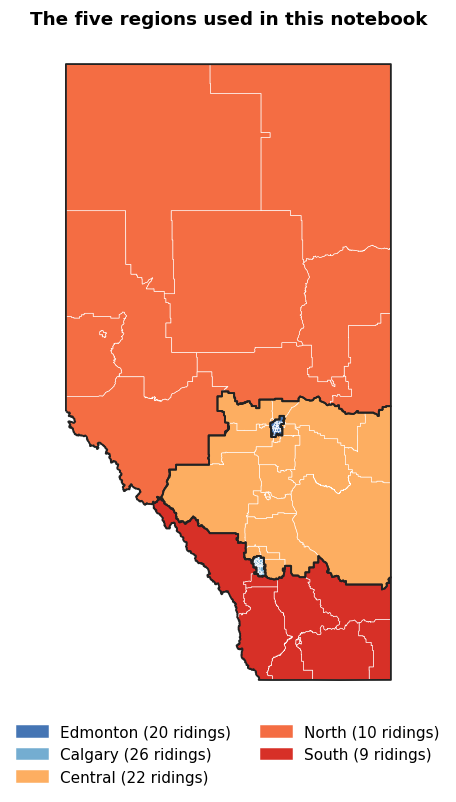

In [3]:
fig, ax = plt.subplots(figsize=(6, 8))
for region in REGION_ORDER:
    gdf[gdf["region"] == region].plot(ax=ax, color=REGION_COLOURS[region], **RIDING_LINES)
outlines.boundary.plot(ax=ax, **REGION_LINES)
ax.legend(handles=[mpatches.Patch(color=REGION_COLOURS[r], label=f"{r} ({(gdf['region'] == r).sum()} ridings)")
                   for r in REGION_ORDER], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
ax.set_title("The five regions used in this notebook")
ax.set_axis_off()
plt.show()

## 2. The map
**How to read it.** Each shape is one riding, coloured by its Option 2 share: pale yellow means little support, dark red means more. Thin white lines separate ridings; thicker dark lines mark region borders. Stars mark the ridings where Option 2 won a majority. City ridings are too small to see on the provincial map, so Calgary and Edmonton are enlarged on the right with each riding's share printed on it.

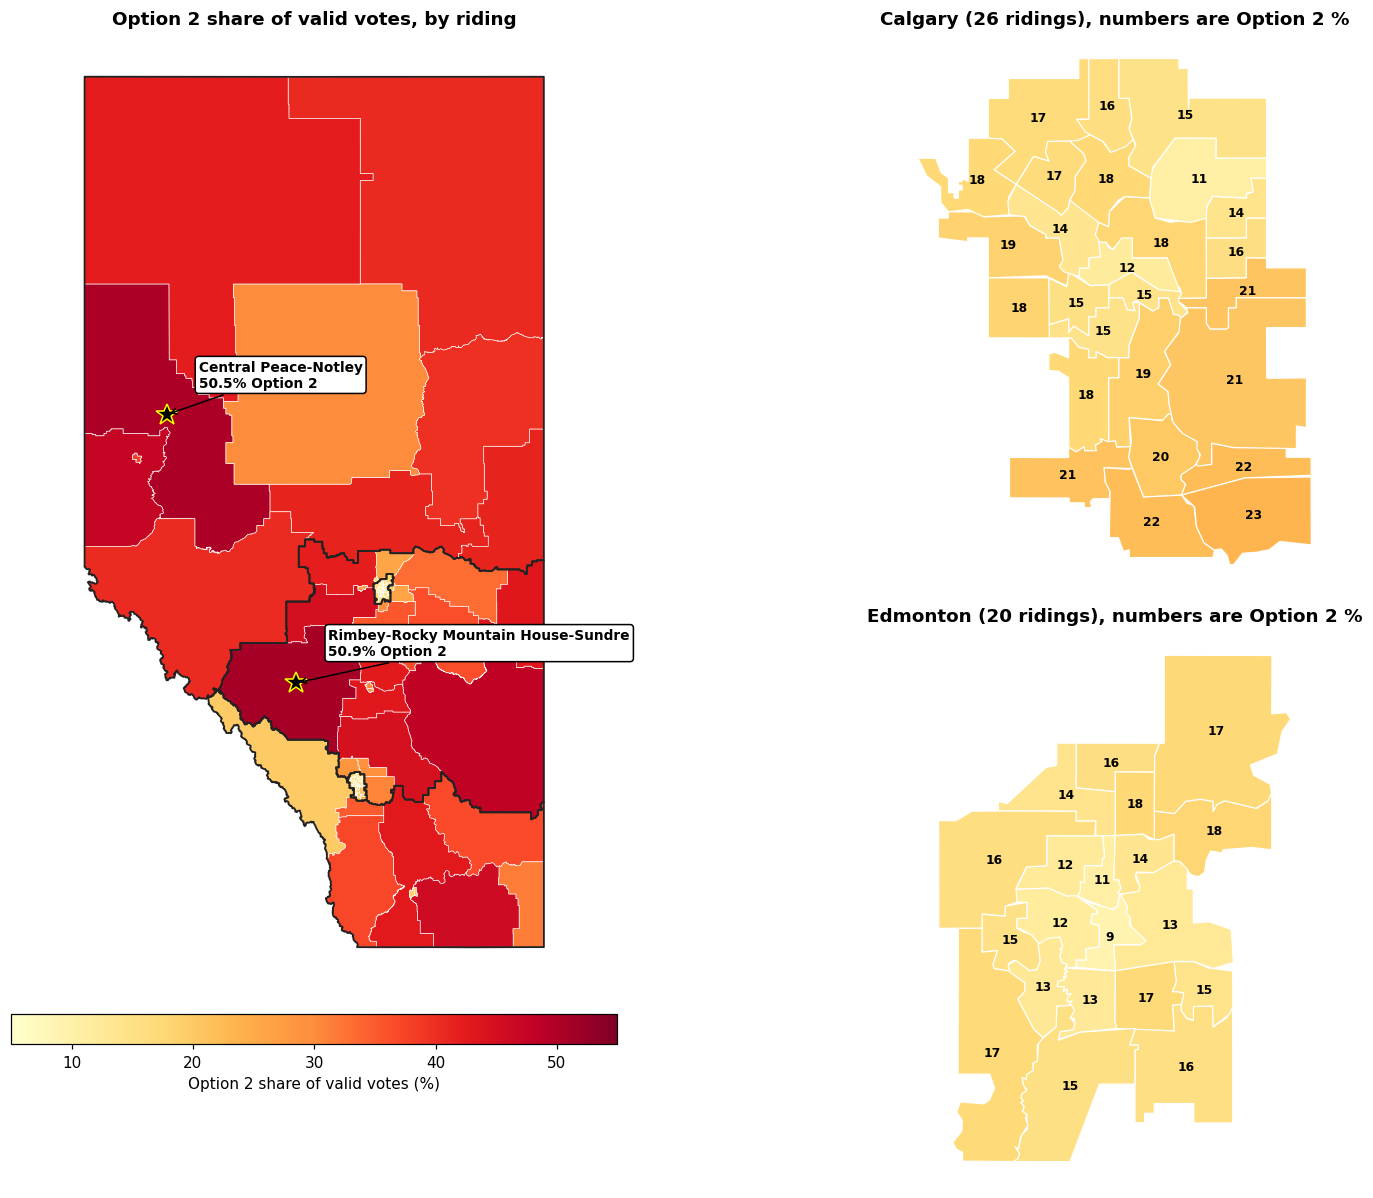

**What it shows.** The strongest Option 2 result was Rimbey-Rocky Mountain House-Sundre (50.9%)
and the weakest was Edmonton-Strathcona (9.3%). No riding in Calgary or Edmonton gave
Option 2 more than 23.3%, below the provincial result of 25.05%. The darker
areas are rural: the Peace Country in the northwest, west-central Alberta and much of the east. The pale strip
along the Rockies is Banff-Kananaskis.

In [4]:
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1.0])
ax_main, ax_cal, ax_edm = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])

gdf.plot(column="option2_pct", cmap=CMAP, norm=NORM, ax=ax_main, **RIDING_LINES)
outlines.boundary.plot(ax=ax_main, **REGION_LINES)
for _, r in over_50.iterrows():
    ax_main.plot(r["lon"], r["lat"], marker="*", markersize=15, color="black", markeredgecolor="yellow")
    ax_main.annotate(f"{r['ed_name'].title()}\n{r['option2_pct']:.1f}% Option 2", xy=(r["lon"], r["lat"]),
                     xytext=(r["lon"] + 0.7, r["lat"] + 0.35), fontsize=9, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black"),
                     arrowprops=dict(arrowstyle="->", color="black"))
ax_main.set_title("Option 2 share of valid votes, by riding")
ax_main.set_axis_off()
sm = plt.cm.ScalarMappable(norm=NORM, cmap=CMAP)
fig.colorbar(sm, ax=ax_main, orientation="horizontal", shrink=0.6, pad=0.02,
             label="Option 2 share of valid votes (%)")

for ax, region in ((ax_cal, "Calgary"), (ax_edm, "Edmonton")):
    sub = gdf[gdf["region"] == region]
    sub.plot(column="option2_pct", cmap=CMAP, norm=NORM, edgecolor="white", linewidth=0.8, ax=ax)
    for _, r in sub.iterrows():
        ax.text(r["lon"], r["lat"], f"{r['option2_pct']:.0f}", fontsize=8, ha="center", va="center", fontweight="bold")
    ax.set_title(f"{region} ({len(sub)} ridings), numbers are Option 2 %")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

hi, lo = gdf.loc[gdf["option2_pct"].idxmax()], gdf.loc[gdf["option2_pct"].idxmin()]
city = gdf[gdf["region"].isin(["Calgary", "Edmonton"])]
note(f"""**What it shows.** The strongest Option 2 result was {hi['ed_name'].title()} ({pct(hi['option2_pct'])})
and the weakest was {lo['ed_name'].title()} ({pct(lo['option2_pct'])}). No riding in Calgary or Edmonton gave
Option 2 more than {pct(city['option2_pct'].max())}, below the provincial result of {pct(prov_share, 2)}. The darker
areas are rural: the Peace Country in the northwest, west-central Alberta and much of the east. The pale strip
along the Rockies is Banff-Kananaskis.""")

## 3. Why the map exaggerates Option 2
Rural ridings cover huge areas with few voters; city ridings are tiny with many. A map coloured by riding therefore makes Option 2 look stronger than it was, because most of the coloured area belongs to rural ridings. The chart below compares each region's share of Alberta's land with its share of the votes.

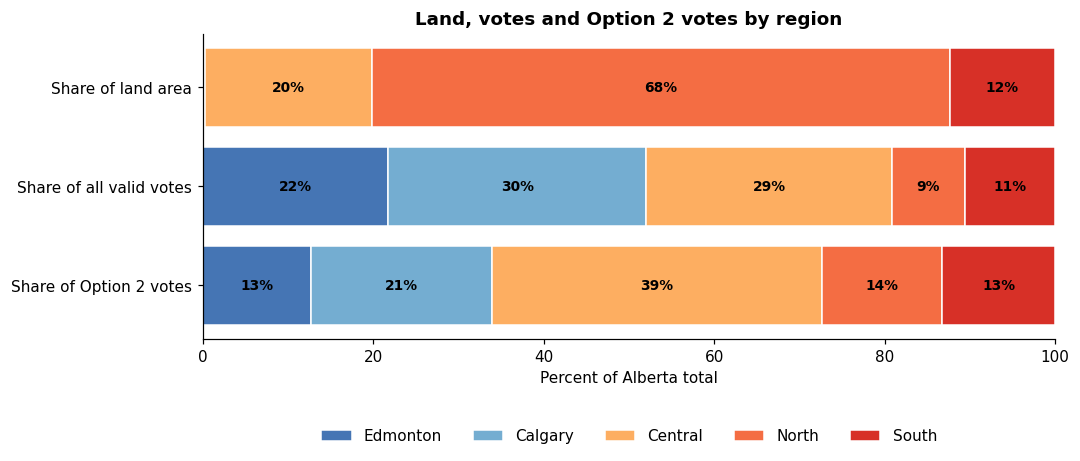

**What it shows.** The North covers 68% of Alberta's land but
cast only 9% of the valid votes. Calgary and Edmonton
together cover well under 1% of the land but cast 52% of the votes, and
34% of all Option 2 votes. The largest single source of Option 2 votes was
Central Alberta (39%).

,Ridings,Area (km²),Valid votes,Option 2 votes,Option 2 share (%)
Region,,,,,
Edmonton,20,781,451834,65797,14.6
Calgary,26,848,629038,110893,17.6
Central,22,130006,598218,201154,33.6
North,10,449797,176672,73485,41.6
South,9,82152,220787,68904,31.2


In [5]:
by_region = gdf.groupby("region").agg(
    ridings=("ed_code", "size"), area_km2=("area_km2", "sum"),
    valid_votes=("total", "sum"), option2_votes=("choice_2_votes", "sum")).reindex(REGION_ORDER)
shares = 100 * by_region[["area_km2", "valid_votes", "option2_votes"]] / by_region[["area_km2", "valid_votes", "option2_votes"]].sum()
shares.columns = ["Share of land area", "Share of all valid votes", "Share of Option 2 votes"]

fig, ax = plt.subplots(figsize=(10, 3.6))
left = np.zeros(3)
for region in REGION_ORDER:
    vals = shares.loc[region].to_numpy()
    ax.barh(shares.columns, vals, left=left, color=REGION_COLOURS[region], edgecolor="white", label=region)
    for i, v in enumerate(vals):
        if v >= 4:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, fontweight="bold")
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percent of Alberta total")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.set_title("Land, votes and Option 2 votes by region")
plt.show()

cities = shares.loc[["Calgary", "Edmonton"]].sum()
note(f"""**What it shows.** The North covers {pct(shares.loc['North', 'Share of land area'], 0)} of Alberta's land but
cast only {pct(shares.loc['North', 'Share of all valid votes'], 0)} of the valid votes. Calgary and Edmonton
together cover well under 1% of the land but cast {pct(cities['Share of all valid votes'], 0)} of the votes, and
{pct(cities['Share of Option 2 votes'], 0)} of all Option 2 votes. The largest single source of Option 2 votes was
Central Alberta ({pct(shares.loc['Central', 'Share of Option 2 votes'], 0)}).""")

table = by_region.assign(**{"Option 2 share (%)": 100 * by_region["option2_votes"] / by_region["valid_votes"]})
table = table.rename(columns={"ridings": "Ridings", "area_km2": "Area (km²)", "valid_votes": "Valid votes",
                              "option2_votes": "Option 2 votes"})
table.index.name = "Region"
table.round({"Area (km²)": 0, "Option 2 share (%)": 1}).astype({"Area (km²)": int})

## 4. Every riding, ranked
**How to read it.** On the left, every riding is a bar, longest at the top, coloured by region. The dotted line is the province-wide result and the red dashed line is 50%. On the right, each box summarises one region: the thick line is the middle riding (the median), the box holds the middle half of ridings, and the whiskers reach the rest (dots are unusual ridings).

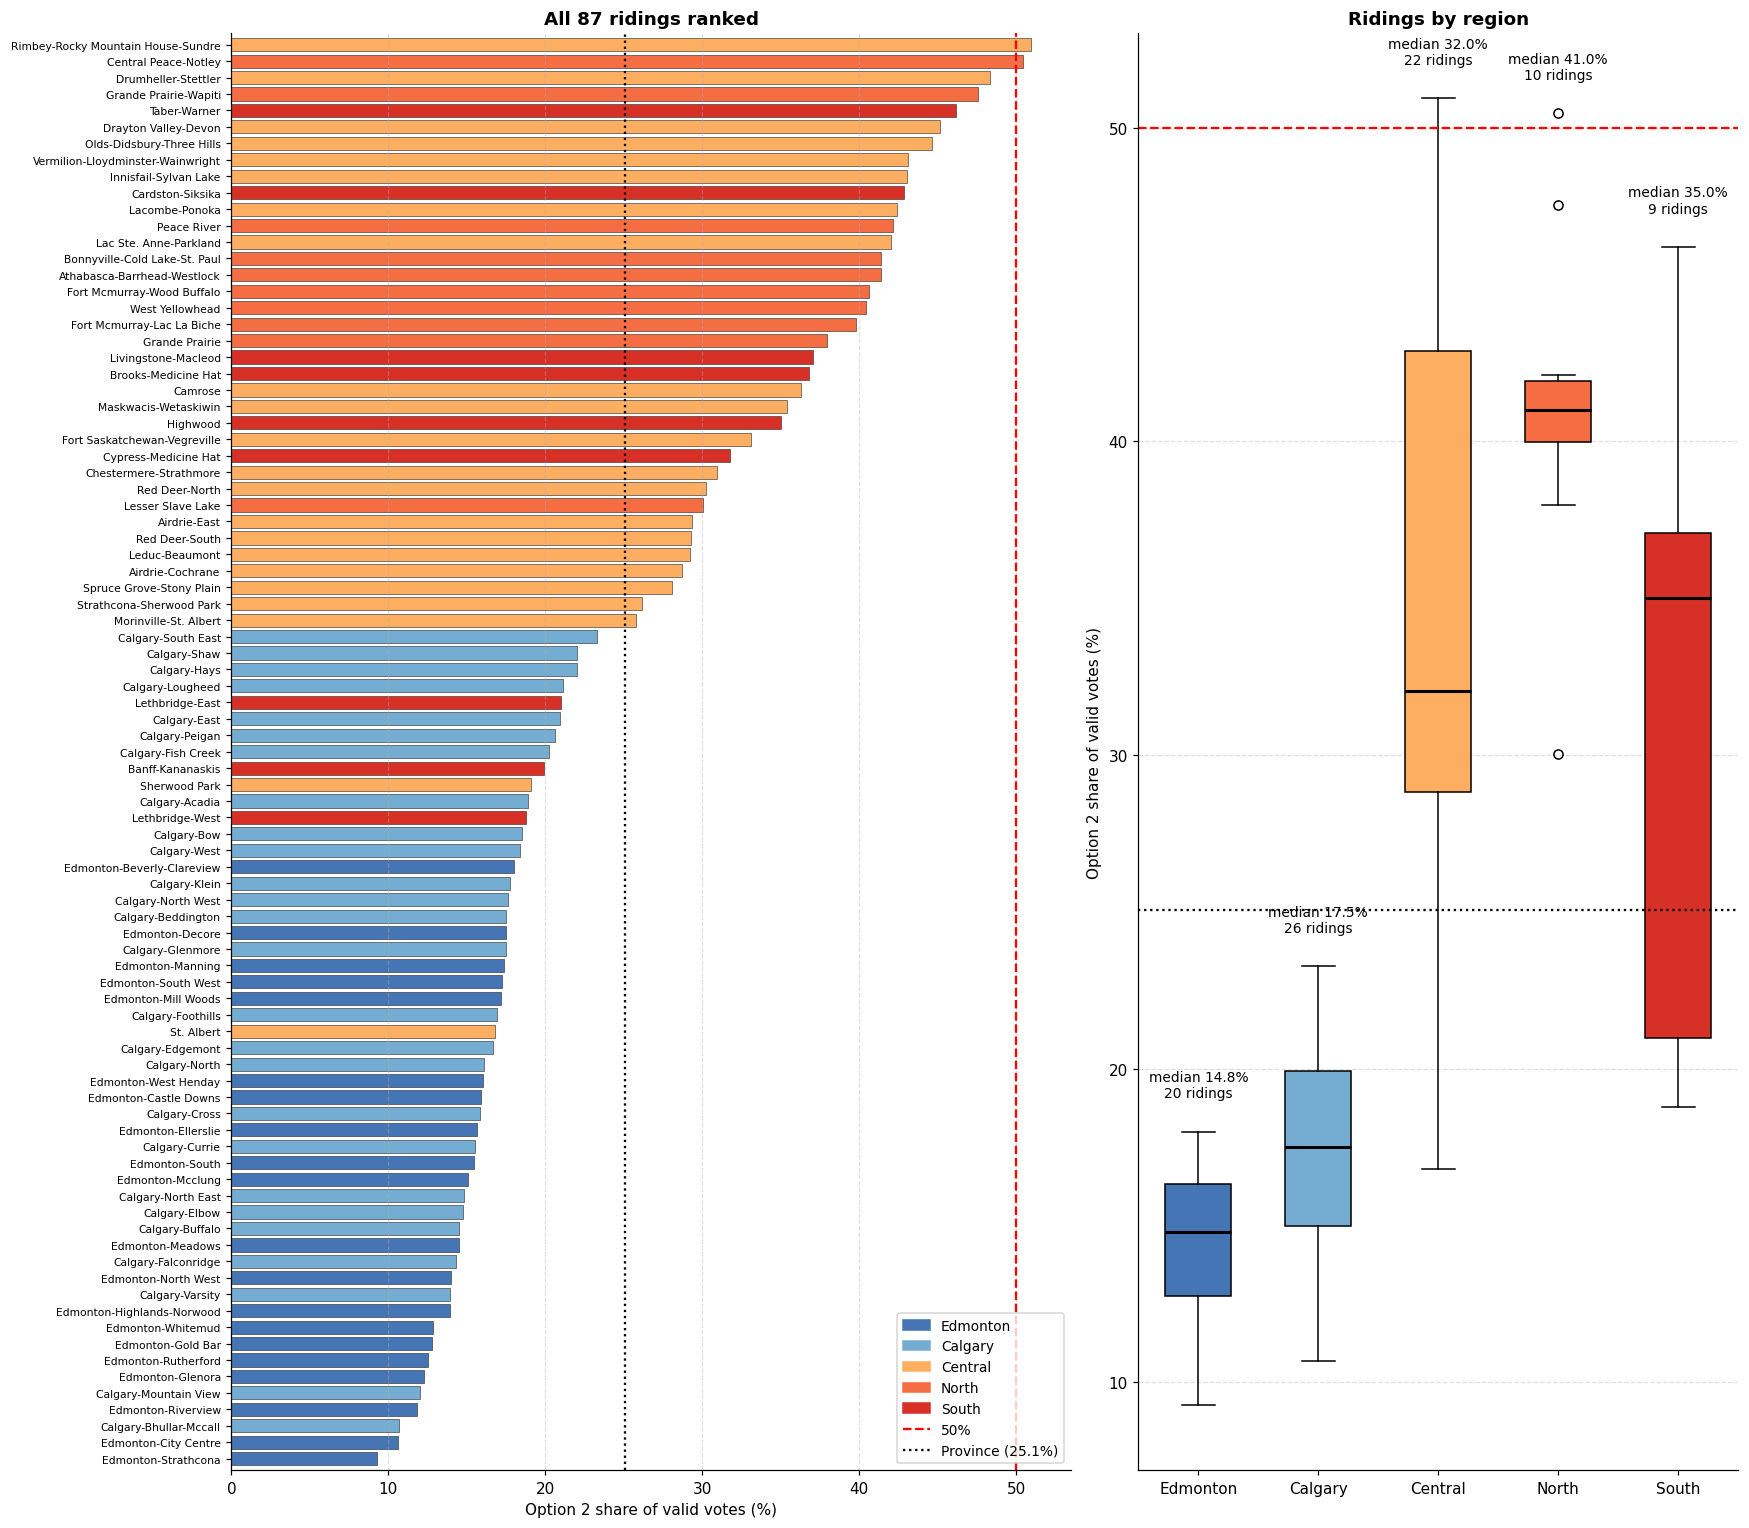

**What it shows.** All 46 Calgary and Edmonton ridings are below the provincial result; Calgary's
south and east come closest. All of the top 20 ridings are outside the two cities
(North: 9, Central: 8, South: 3). Median ridings range from 14.8% (Edmonton) to
41.0% (North). Central Alberta is the most varied region, from its suburbs near Edmonton
and Calgary (low Option 2) to rural ridings near or above 50%.

In [6]:
ranked = gdf.sort_values("option2_pct")
fig, (ax_bar, ax_box) = plt.subplots(1, 2, figsize=(16, 14), gridspec_kw={"width_ratios": [1.4, 1.0]})

ax_bar.barh(np.arange(len(ranked)), ranked["option2_pct"], color=ranked["region"].map(REGION_COLOURS),
            edgecolor="#333333", linewidth=0.4, height=0.8)
ax_bar.axvline(50, color="red", linestyle="--", linewidth=1.5)
ax_bar.axvline(prov_share, color="black", linestyle=":", linewidth=1.5)
ax_bar.set_yticks(np.arange(len(ranked)))
ax_bar.set_yticklabels(ranked["ed_name"].str.title(), fontsize=7)
ax_bar.set_ylim(-0.7, len(ranked) - 0.3)
ax_bar.set_xlabel("Option 2 share of valid votes (%)")
ax_bar.set_title("All 87 ridings ranked")
handles = [mpatches.Patch(color=REGION_COLOURS[r], label=r) for r in REGION_ORDER]
handles += [plt.Line2D([0], [0], color="red", linestyle="--", label="50%"),
            plt.Line2D([0], [0], color="black", linestyle=":", label=f"Province ({prov_share:.1f}%)")]
ax_bar.legend(handles=handles, loc="lower right", fontsize=9)
ax_bar.grid(axis="x", linestyle="--", alpha=0.4)

data = [gdf.loc[gdf["region"] == r, "option2_pct"] for r in REGION_ORDER]
bp = ax_box.boxplot(data, tick_labels=REGION_ORDER, patch_artist=True, widths=0.55)
for patch, r in zip(bp["boxes"], REGION_ORDER):
    patch.set_facecolor(REGION_COLOURS[r])
for med in bp["medians"]:
    med.set(color="black", linewidth=2)
for i, d in enumerate(data, start=1):
    ax_box.text(i, d.max() + 1, f"median {d.median():.1f}%\n{len(d)} ridings", ha="center", va="bottom", fontsize=9)
ax_box.axhline(50, color="red", linestyle="--", linewidth=1.5)
ax_box.axhline(prov_share, color="black", linestyle=":", linewidth=1.5)
ax_box.set_ylabel("Option 2 share of valid votes (%)")
ax_box.set_title("Ridings by region")
ax_box.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

med = gdf.groupby("region")["option2_pct"].median()
top20 = ranked.tail(20)
n_city_below = (city["option2_pct"] < prov_share).sum()
city_text = (f"All {len(city)}" if n_city_below == len(city) else f"{n_city_below} of the {len(city)}")
note(f"""**What it shows.** {city_text} Calgary and Edmonton ridings are below the provincial result; Calgary's
south and east come closest. All of the top 20 ridings are outside the two cities
({', '.join(f"{r}: {n}" for r, n in top20['region'].value_counts().items())}). Median ridings range from {pct(med.min())} ({med.idxmin()}) to
{pct(med.max())} ({med.idxmax()}). Central Alberta is the most varied region, from its suburbs near Edmonton
and Calgary (low Option 2) to rural ridings near or above 50%.""")

## 5. Is support clustered on the map?
Neighbouring ridings often vote alike. The question is whether they do so **more than chance would produce**.

**How we measure it.** *Moran's I* is a single number for the whole map. It is about 0 when a riding's result says nothing about its neighbours' results, and gets closer to 1 the more alike neighbours are. **Neighbours** here are ridings that share a border.

**How we test it.** We randomly shuffle the results among the 87 ridings 9,999 times, which keeps the same numbers but scrambles where they sit, and compute Moran's I for each shuffled map. If the real map is more clustered than almost all shuffled maps, the clustering is unlikely to be chance.

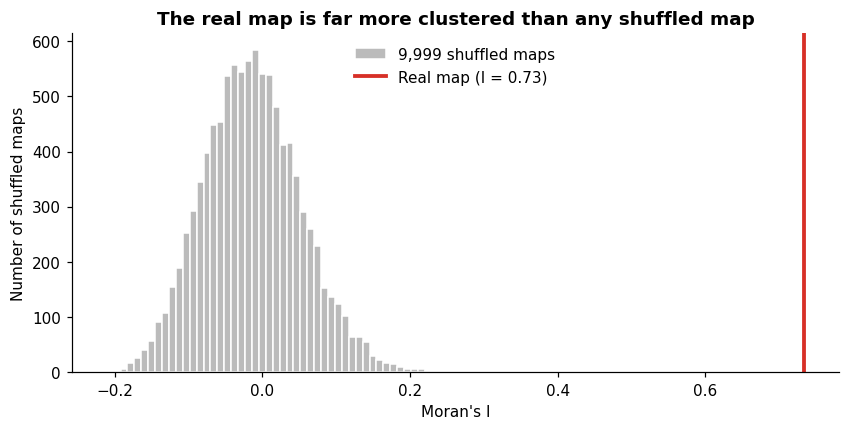

**What it shows.** Moran's I is **0.73**. None of the 9,999 shuffled maps came close (the
highest was 0.26), so the p-value is 0.0001, the smallest this test can report. Option 2
support is strongly clustered: ridings with high support tend to border other high-support ridings, and low
next to low.

In [7]:
W = queen_weights(gdf)
i_obs, p_obs, i_perm = moran_test(y, W, N_PERMUTATIONS)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(i_perm, bins=50, color="#bbbbbb", edgecolor="white", label="9,999 shuffled maps")
ax.axvline(i_obs, color="#d73027", linewidth=2.5, label=f"Real map (I = {i_obs:.2f})")
ax.set_xlabel("Moran's I")
ax.set_ylabel("Number of shuffled maps")
ax.set_title("The real map is far more clustered than any shuffled map")
ax.legend(frameon=False)
plt.show()

note(f"""**What it shows.** Moran's I is **{i_obs:.2f}**. None of the {N_PERMUTATIONS:,} shuffled maps came close (the
highest was {i_perm.max():.2f}), so the p-value is {p_obs:.4f}, the smallest this test can report. Option 2
support is strongly clustered: ridings with high support tend to border other high-support ridings, and low
next to low.""")

**Does the answer depend on how we define "neighbour"?** Below, the same statistic is computed with other definitions: each riding's 3, 5, 7 or 10 nearest ridings (measured centre to centre). If the conclusion held only for one definition, it would be fragile.

In [8]:
xy = gdf[["x", "y"]].to_numpy()
sens = {"Shared border (main result)": i_obs}
sens.update({f"{k} nearest ridings": morans_i(y, knn_weights(xy, k)) for k in (3, 5, 7, 10)})
sens = pd.Series(sens, name="Moran's I").round(2)
note(f"""**What it shows.** Every definition gives a clearly positive value, from {sens.min():.2f} to
{sens.max():.2f}. Values fall as more distant ridings are counted as neighbours, which is expected:
the further apart two ridings are, the less alike they tend to be. The conclusion does not depend on the choice.""")
sens.to_frame()

**What it shows.** Every definition gives a clearly positive value, from 0.49 to
0.73. Values fall as more distant ridings are counted as neighbours, which is expected:
the further apart two ridings are, the less alike they tend to be. The conclusion does not depend on the choice.

,Moran's I
Shared border (main result),0.73
3 nearest ridings,0.67
5 nearest ridings,0.64
7 nearest ridings,0.57
10 nearest ridings,0.49


## 6. Is it just city versus country?
Sections 2 to 4 showed large gaps between regions. City ridings border city ridings and rural ridings border rural ridings, so the clustering in section 5 could simply be the urban-rural divide. To check, we subtract each region's average from its ridings' results and repeat the test on what is left. A riding then counts as "high" only if it is high **for its region**.

In [9]:
region_mean = gdf.groupby("region")["option2_pct"].transform("mean").to_numpy()
resid = y - region_mean
i_res, p_res, _ = moran_test(resid, W, N_PERMUTATIONS)

verdict = ("some clustering remains beyond the regional averages, though it is weak"
           if p_res < ALPHA else "no clear clustering remains once regional averages are removed")
note(f"""**What it shows.** After removing regional averages, Moran's I drops from {i_obs:.2f} to **{i_res:.2f}**
(p = {p_res:.3f}). Most of the clustering is the difference between regions: {verdict}. In other words,
knowing a riding's region tells you most of what its neighbours tell you. This depends on the region labels,
which have not been independently verified.""")

**What it shows.** After removing regional averages, Moran's I drops from 0.73 to **0.11**
(p = 0.033). Most of the clustering is the difference between regions: some clustering remains beyond the regional averages, though it is weak. In other words,
knowing a riding's region tells you most of what its neighbours tell you. This depends on the region labels,
which have not been independently verified.

## 7. Where are the clusters?
Moran's I describes the whole map. To see **which** ridings drive it, we compute a local version for each riding (often called **LISA**) and sort ridings into four groups:

- **High-High** (red): high Option 2, surrounded by high Option 2. A hotspot.
- **Low-Low** (dark blue): low Option 2, surrounded by low. A coldspot.
- **High-Low** (orange): high Option 2, surrounded by low. An outlier.
- **Low-High** (light blue): low Option 2, surrounded by high. An outlier.

Each riding is tested with the same shuffling idea as section 5: its neighbours are replaced by random ridings 9,999 times. Ridings whose pattern could easily be chance (p ≥ 0.05) are grey. Groups with no significant ridings are left out of the legend.

The first figure maps the results, with Calgary and Edmonton enlarged because their ridings are too small to see on the provincial map. **How to read the second figure.** Each dot is a riding. Left to right is the riding's own Option 2 result; bottom to top is its neighbours' average. Both are in standard units, where 0 is the average riding. Dots in the top-right are hotspots, bottom-left are coldspots.

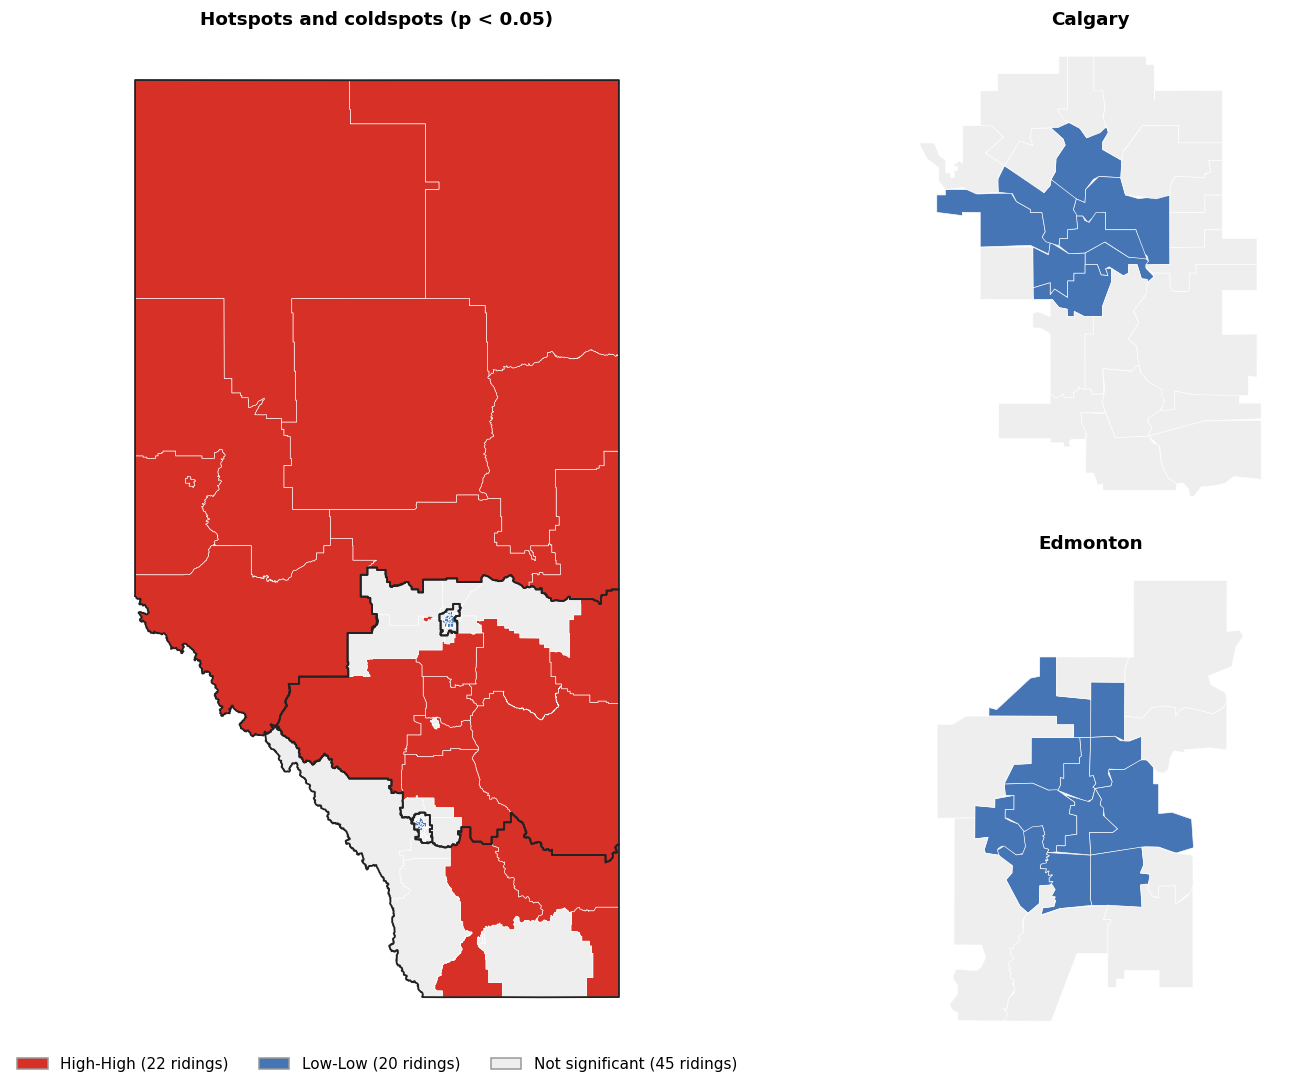

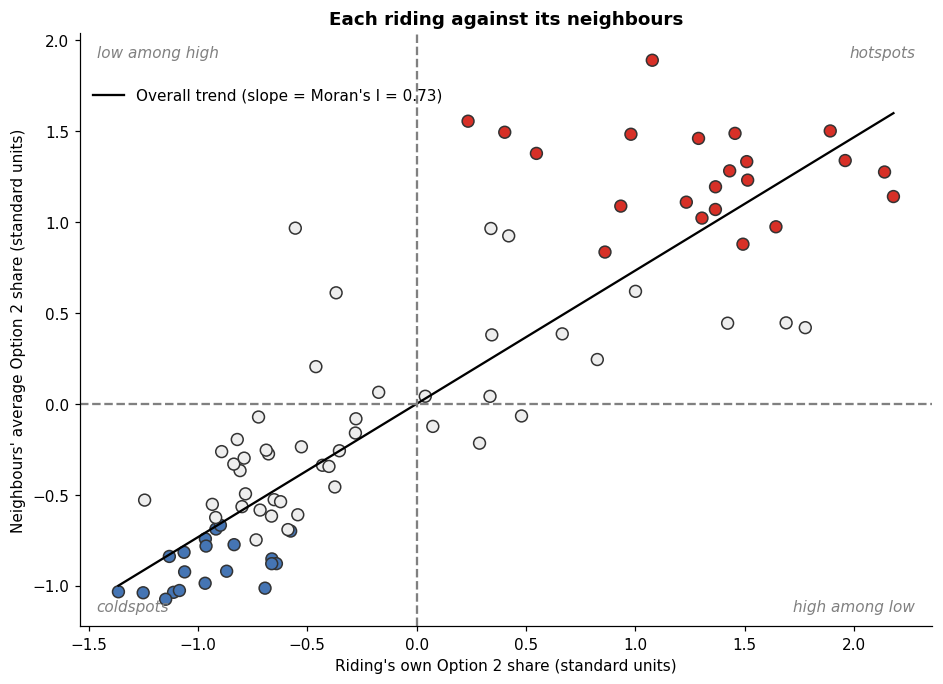

**What it shows.** 22 ridings are **hotspots** (North 10, Central 9, South 3). They form one large area
covering every northern riding, rural central Alberta, and the southeast around Medicine Hat and Brooks.
20 are **coldspots** (Edmonton 12, Calgary 8), mostly the central and older parts of both cities; the newer
outer city ridings are not significant. No riding is a significant outlier. The remaining 45 ridings
show no pattern beyond chance. They include the suburbs and towns around both cities, Red Deer, Lethbridge
and the southwest foothills, which sit between the high and low areas.

**Caution.** With 87 separate tests at the 5% level, about 4 ridings could be flagged by chance alone, so treat
individual borderline ridings with care. The broad picture (rural hotspots, urban coldspots) is robust.

In [10]:
lisa = local_moran(y, W, N_PERMUTATIONS)
gdf["lisa"] = np.where(lisa["p"] < ALPHA, lisa["quadrant"], "Not significant")
gdf["lisa_p"] = lisa["p"].to_numpy()

present = [name for name in LISA_COLOURS if (gdf["lisa"] == name).any()]

fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1.0])
ax_map, ax_cal, ax_edm = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
for ax, sub_gdf in ((ax_map, gdf), (ax_cal, gdf[gdf["region"] == "Calgary"]), (ax_edm, gdf[gdf["region"] == "Edmonton"])):
    for name in present:
        part = sub_gdf[sub_gdf["lisa"] == name]
        if len(part):
            part.plot(color=LISA_COLOURS[name], ax=ax, **RIDING_LINES)
    ax.set_axis_off()
outlines.boundary.plot(ax=ax_map, **REGION_LINES)
ax_map.legend(handles=[mpatches.Patch(facecolor=LISA_COLOURS[n], edgecolor="#999999",
                                      label=f"{n} ({(gdf['lisa'] == n).sum()} ridings)") for n in present],
              loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
ax_map.set_title("Hotspots and coldspots (p < 0.05)")
ax_cal.set_title("Calgary")
ax_edm.set_title("Edmonton")
plt.tight_layout()
plt.show()

fig, ax_sc = plt.subplots(figsize=(10, 7))
colours = gdf["lisa"].map(LISA_COLOURS)
ax_sc.scatter(lisa["z"], lisa["lag"], c=colours, s=60, edgecolor="#333333")
xs = np.linspace(lisa["z"].min(), lisa["z"].max(), 20)
ax_sc.plot(xs, i_obs * xs, color="black", linewidth=1.5, label=f"Overall trend (slope = Moran's I = {i_obs:.2f})")
ax_sc.axhline(0, color="grey", linestyle="--")
ax_sc.axvline(0, color="grey", linestyle="--")
for (tx, ty, label) in ((0.98, 0.98, "hotspots"), (0.02, 0.02, "coldspots"), (0.98, 0.02, "high among low"),
                        (0.02, 0.98, "low among high")):
    ax_sc.text(tx, ty, label, transform=ax_sc.transAxes, ha="right" if tx > 0.5 else "left",
               va="top" if ty > 0.5 else "bottom", color="grey", fontsize=10, style="italic")
ax_sc.set_xlabel("Riding's own Option 2 share (standard units)")
ax_sc.set_ylabel("Neighbours' average Option 2 share (standard units)")
ax_sc.set_title("Each riding against its neighbours")
ax_sc.legend(loc="upper left", bbox_to_anchor=(0, 0.93), frameon=False)
plt.show()

counts = gdf["lisa"].value_counts()
hh = gdf[gdf["lisa"] == "High-High"]
ll = gdf[gdf["lisa"] == "Low-Low"]
outl = gdf[gdf["lisa"].isin(["High-Low", "Low-High"])]
def by_region(frame):
    return ", ".join(f"{r} {n}" for r, n in frame["region"].value_counts().items())
outlier_text = ("No riding is a significant outlier." if outl.empty else
                f"{len(outl)} ridings are significant outliers: {', '.join(outl['ed_name'].str.title())}.")
note(f"""**What it shows.** {len(hh)} ridings are **hotspots** ({by_region(hh)}). They form one large area
covering every northern riding, rural central Alberta, and the southeast around Medicine Hat and Brooks.
{len(ll)} are **coldspots** ({by_region(ll)}), mostly the central and older parts of both cities; the newer
outer city ridings are not significant. {outlier_text} The remaining {counts.get('Not significant', 0)} ridings
show no pattern beyond chance. They include the suburbs and towns around both cities, Red Deer, Lethbridge
and the southwest foothills, which sit between the high and low areas.

**Caution.** With 87 separate tests at the 5% level, about 4 ridings could be flagged by chance alone, so treat
individual borderline ridings with care. The broad picture (rural hotspots, urban coldspots) is robust.""")

## 8. Did turnout matter?
Turnout is the share of registered electors who cast a ballot. One common idea is that motivated voters turn out more, so higher turnout could go with higher Option 2 support, or lower. Each dot below is a riding.

**Two cautions.** First, this compares ridings, not people: it cannot say whether Option 2 voters themselves were more likely to vote. Second, turnout here uses the elector counts printed in the Elections Alberta workbooks, which are higher than the counts in the news release, so all turnouts are a few points lower than the official headline figure (see `other/sources.md`).

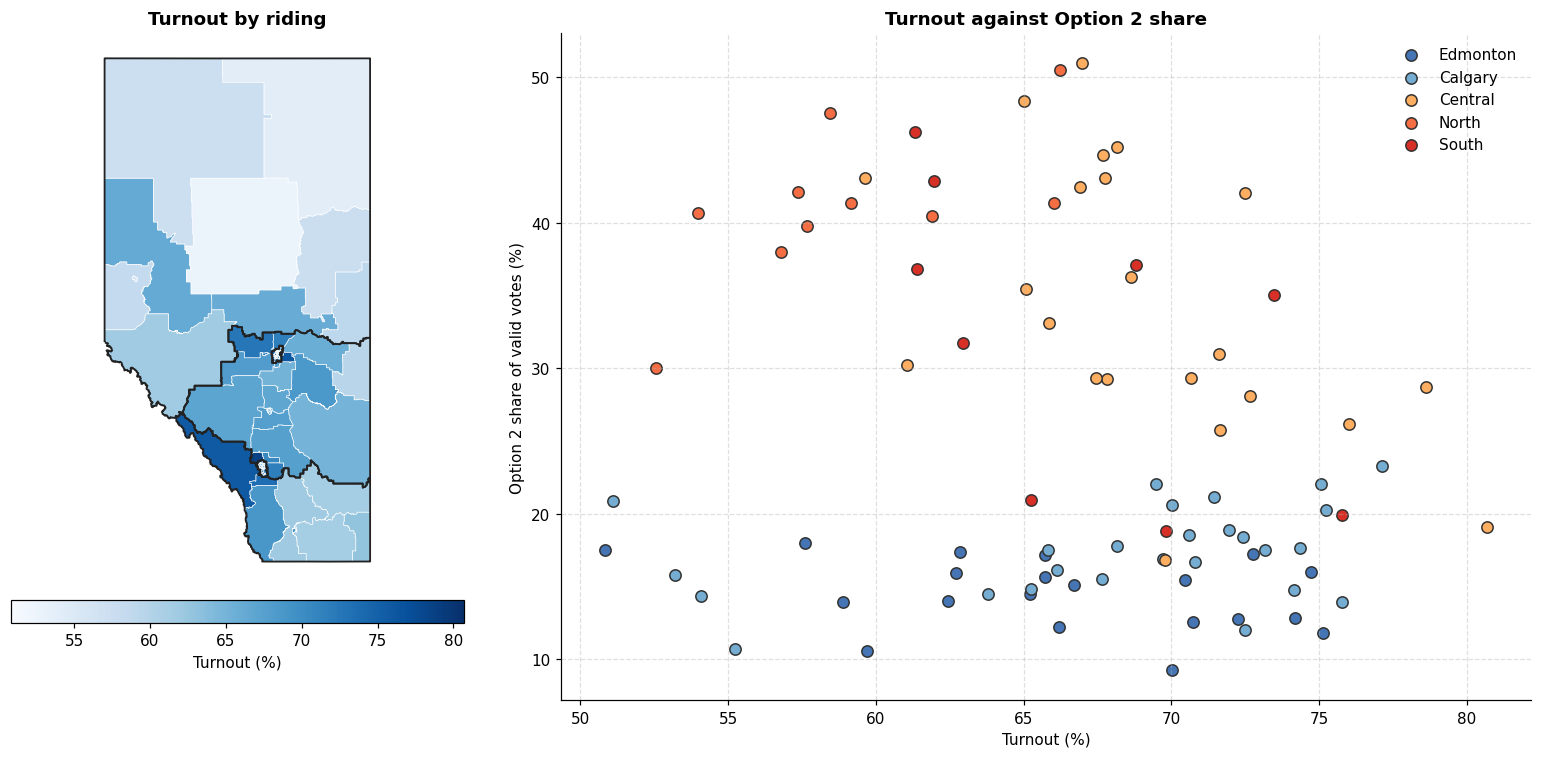

**What it shows.** Turnout ranged from 50.8% (Edmonton-Decore) to
80.7% (Sherwood Park). By region, median turnout was lowest in the
North (58.0%) and highest in Calgary (70.3%). Across all ridings the rank correlation between turnout
and Option 2 share is **-0.18** (it runs from -1 to 1, with 0 meaning no relationship), which is weak.
Within regions, the relationship is sometimes moderately strong but points in opposite directions: higher turnout
goes with more Option 2 support in some regions and less in others (table below). Each region has only 9 to 26
ridings, so these within-region figures are fragile. There is **no clear, consistent link** between turnout and
Option 2 support.

,Rank correlation
Edmonton,-0.32
Calgary,0.31
Central,-0.62
North,0.61
South,-0.70


In [11]:
fig, (ax_map, ax_sc) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [0.8, 1.2]})
gdf.plot(column="turnout_pct", cmap="Blues", ax=ax_map, legend=True, **RIDING_LINES,
         legend_kwds={"label": "Turnout (%)", "orientation": "horizontal", "shrink": 0.7, "pad": 0.02})
outlines.boundary.plot(ax=ax_map, **REGION_LINES)
ax_map.set_title("Turnout by riding")
ax_map.set_axis_off()

for region in REGION_ORDER:
    sub = gdf[gdf["region"] == region]
    ax_sc.scatter(sub["turnout_pct"], sub["option2_pct"], color=REGION_COLOURS[region], s=55,
                  edgecolor="#333333", label=region)
ax_sc.set_xlabel("Turnout (%)")
ax_sc.set_ylabel("Option 2 share of valid votes (%)")
ax_sc.set_title("Turnout against Option 2 share")
ax_sc.legend(frameon=False)
ax_sc.grid(linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

rho_all = gdf[["turnout_pct", "option2_pct"]].corr(method="spearman").iloc[0, 1]
rho_reg = pd.Series({r: gdf.loc[gdf["region"] == r, ["turnout_pct", "option2_pct"]].corr(method="spearman").iloc[0, 1]
                     for r in REGION_ORDER}, name="Rank correlation").round(2)
low_t = gdf.loc[gdf["turnout_pct"].idxmin()]
high_t = gdf.loc[gdf["turnout_pct"].idxmax()]
t_med = gdf.groupby("region")["turnout_pct"].median()
note(f"""**What it shows.** Turnout ranged from {pct(low_t['turnout_pct'])} ({low_t['ed_name'].title()}) to
{pct(high_t['turnout_pct'])} ({high_t['ed_name'].title()}). By region, median turnout was lowest in the
{t_med.idxmin()} ({pct(t_med.min())}) and highest in {t_med.idxmax()} ({pct(t_med.max())}). Across all ridings the rank correlation between turnout
and Option 2 share is **{rho_all:.2f}** (it runs from -1 to 1, with 0 meaning no relationship), which is weak.
Within regions, the relationship is sometimes moderately strong but points in opposite directions: higher turnout
goes with more Option 2 support in some regions and less in others (table below). Each region has only 9 to 26
ridings, so these within-region figures are fragile. There is **no clear, consistent link** between turnout and
Option 2 support.""")
rho_reg.to_frame()

# Part 2: All ten questions

Question 10 was one of ten questions on the same ballot. Questions 1 to 5 were about immigration and voting rules; questions 6 to 9 asked whether Alberta should work with other provinces to change the Constitution. Part 2 asks whether the same geography shows up on every question, and where Question 10 broke from the rest.

**"Support" in Part 2** means the Yes share of valid votes for questions 1 to 9, and the Option 2 share for Question 10. In every case it is the side asking for more provincial power or for change, so the questions can be compared directly. Short labels such as "Q7 Abolish Senate" are used in charts; the full wording is in the first table.

## 9. The ten questions

In [12]:
from common import ANALYSIS
from matplotlib.colors import TwoSlopeNorm
from spatial import QUESTION_LABELS, load_support

support, votes = load_support()
support = support.loc[gdf["ed_code"]].reset_index(drop=True)   # same riding order as the maps
QS = list(support.columns)

prov = votes.groupby("question_number")[["support_votes", "total"]].sum()
prov_support = 100 * prov["support_votes"] / prov["total"]
wording = (pd.read_csv(ANALYSIS / "ed_results_2026.csv").groupby("question_number")["question_text"].first())

overview = pd.DataFrame({
    "Question": [QUESTION_LABELS[q] for q in QS],
    "Wording": [wording[q] for q in QS],
    "Support, province (%)": [round(prov_support[q], 1) for q in QS],
    "Majority support?": ["Yes" if prov_support[q] > 50 else "No" for q in QS],
    "Ridings with majority support": [int((support[q] > 50).sum()) for q in QS],
    "Lowest riding (%)": [round(support[q].min(), 1) for q in QS],
    "Highest riding (%)": [round(support[q].max(), 1) for q in QS],
}).set_index("Question")

passed = [q for q in QS if prov_support[q] > 50]
note(f"""**What it shows.** {len(passed)} of the 10 questions won majority support province-wide
({', '.join(f'Q{q}' for q in passed)}): the immigration and voting questions. The four constitutional questions
(Q6 to Q9) and Question 10 did not. Support ranged from {pct(prov_support.max())} on
{QUESTION_LABELS[prov_support.idxmax()]} to {pct(prov_support.min())} on {QUESTION_LABELS[prov_support.idxmin()]},
which was far below every other question.""")
overview

**What it shows.** 5 of the 10 questions won majority support province-wide
(Q1, Q2, Q3, Q4, Q5): the immigration and voting questions. The four constitutional questions
(Q6 to Q9) and Question 10 did not. Support ranged from 58.1% on
Q5 Citizenship to vote to 25.1% on Q10 Separation process,
which was far below every other question.

,Wording,"Support, province (%)",Majority support?,Ridings with majority support,Lowest riding (%),Highest riding (%)
Question,,,,,,
Q1 Immigration control,Do you support the Government of Alberta takin...,54.9,Yes,48,27.5,78.5
Q2 Program eligibility,Do you support the Government of Alberta intro...,52.5,Yes,42,24.7,76.8
Q3 Residency wait,Assuming that all Canadian citizens and perman...,53.1,Yes,43,25.7,77.3
Q4 Health/education fee,Assuming that all Canadian citizens and perman...,51.8,Yes,41,24.5,76.3
Q5 Citizenship to vote,Do you support the Government of Alberta intro...,58.1,Yes,62,30.5,81.5
Q6 Provinces pick judges,Do you support the Government of Alberta worki...,45.4,No,33,19.5,74.5
Q7 Abolish Senate,Do you support the Government of Alberta worki...,47.3,No,34,22.0,75.0
Q8 Opt out with funding,Do you support the Government of Alberta worki...,42.4,No,27,17.2,69.3
Q9 Provincial paramountcy,Do you support the Government of Alberta worki...,44.2,No,31,18.5,72.5


**How to read the next chart.** Each row is a question and each dot is one riding, coloured by region. The black diamond is the province-wide result and the dashed line is 50%. A wide spread of dots means ridings disagreed a lot on that question.

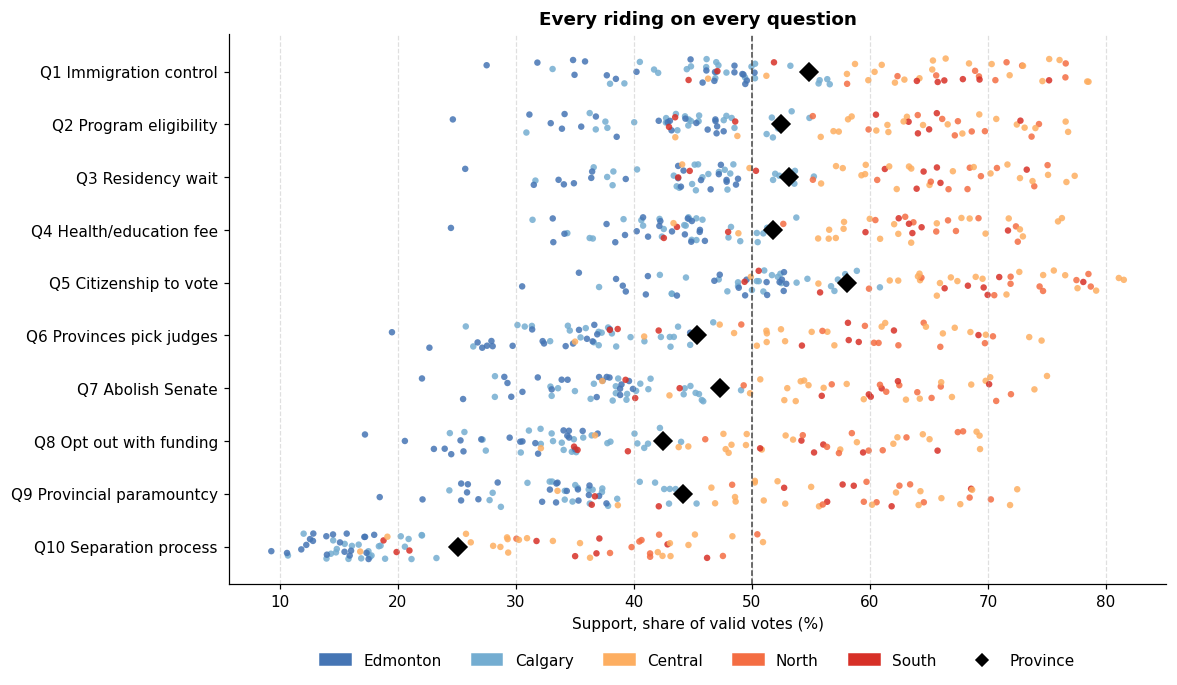

**What it shows.** On every question, ridings disagreed widely: the gap between the lowest and highest
riding ranged from 42 to 55 percentage points. On every question the city ridings
(blue) sit to the left and the North and Central ridings (orange and red) to the right. Questions 1 to 5 had
majority support in 41 to 62 of the 87 ridings, questions 6 to 9 in
27 to 34, and Question 10 in only 2: it shifts the whole pattern
far to the left.

In [13]:
fig, ax = plt.subplots(figsize=(11, 6.5))
rng_jitter = np.random.default_rng(1)
for row, q in enumerate(QS):
    jitter = rng_jitter.uniform(-0.25, 0.25, len(support))
    ax.scatter(support[q], row + jitter, c=gdf["region"].map(REGION_COLOURS), s=18, edgecolor="none", alpha=0.85)
    ax.plot(prov_support[q], row, marker="D", color="black", markersize=8)
ax.axvline(50, color="#444444", linestyle="--", linewidth=1)
ax.set_yticks(range(len(QS)))
ax.set_yticklabels([QUESTION_LABELS[q] for q in QS])
ax.invert_yaxis()
ax.set_xlabel("Support, share of valid votes (%)")
ax.set_title("Every riding on every question")
handles = [mpatches.Patch(color=REGION_COLOURS[r], label=r) for r in REGION_ORDER]
handles.append(plt.Line2D([0], [0], marker="D", color="black", linestyle="none", label="Province"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=6, frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.show()

spread = support.max() - support.min()
maj = (support > 50).sum()
note(f"""**What it shows.** On every question, ridings disagreed widely: the gap between the lowest and highest
riding ranged from {spread.min():.0f} to {spread.max():.0f} percentage points. On every question the city ridings
(blue) sit to the left and the North and Central ridings (orange and red) to the right. Questions 1 to 5 had
majority support in {maj[[1, 2, 3, 4, 5]].min()} to {maj[[1, 2, 3, 4, 5]].max()} of the 87 ridings, questions 6 to 9 in
{maj[[6, 7, 8, 9]].min()} to {maj[[6, 7, 8, 9]].max()}, and Question 10 in only {maj[10]}: it shifts the whole pattern
far to the left.""")

## 10. Ten maps
**How to read it.** Each small map is one question. Green means majority support, brown means majority against, and pale means close to 50-50. All ten maps use the same colour scale, so colours can be compared across maps. City ridings are too small to see at this size; sections 9 and 11 show them.

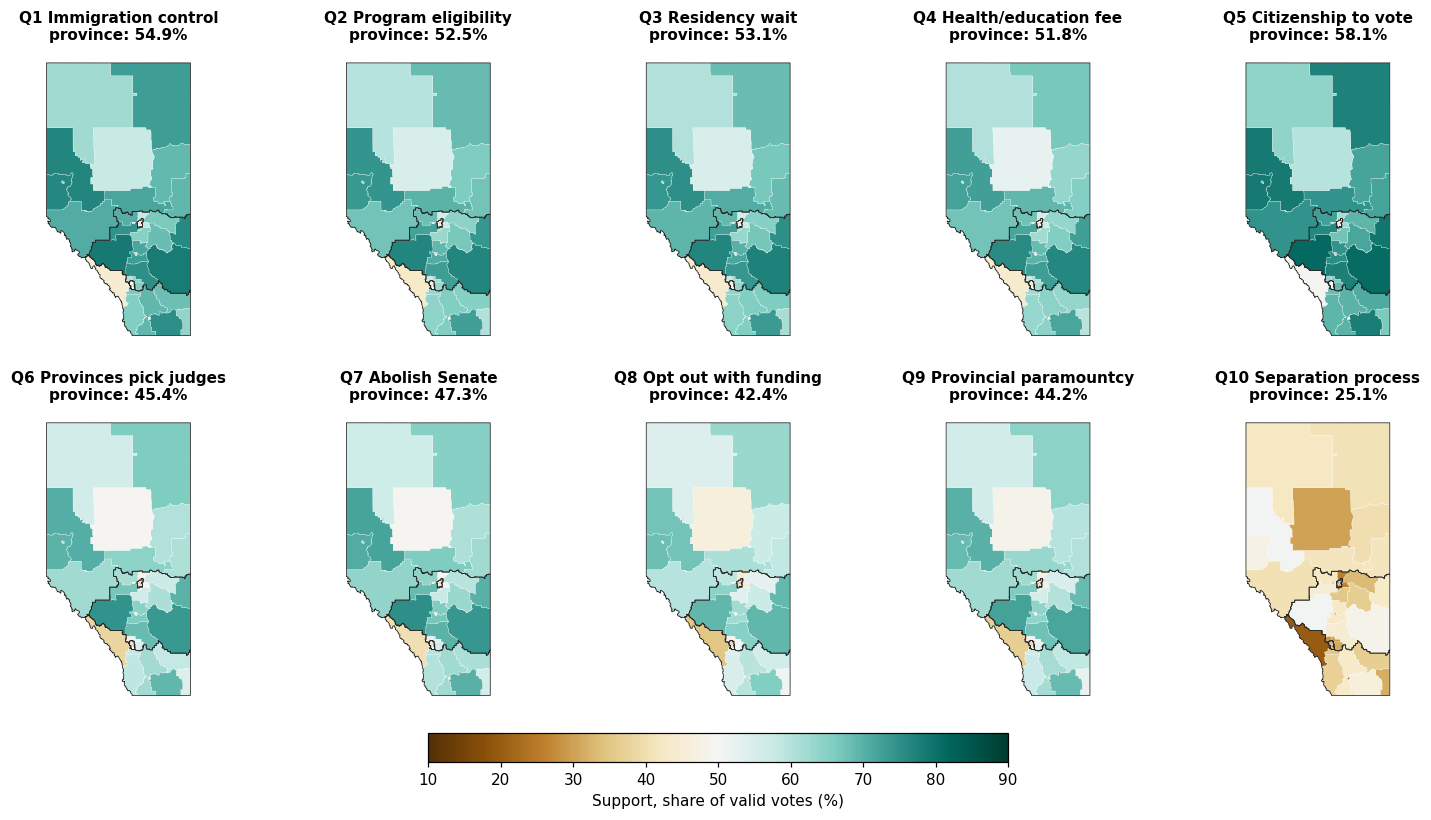

**What it shows.** The same picture repeats on every map: the most support in the north and across rural
central and eastern Alberta, the least in Calgary, Edmonton and along the mountains west of Calgary. What changes
from question to question is mostly how much of the province is green, not where the green is.

In [14]:
SUPPORT_NORM = TwoSlopeNorm(vmin=10, vcenter=50, vmax=90)
SUPPORT_CMAP = "BrBG"

fig, axes = plt.subplots(2, 5, figsize=(17, 9.5))
for ax, q in zip(axes.flat, QS):
    gdf.assign(s=support[q].to_numpy()).plot(column="s", cmap=SUPPORT_CMAP, norm=SUPPORT_NORM, ax=ax,
                                             edgecolor="white", linewidth=0.15)
    outlines.boundary.plot(ax=ax, color="#222222", linewidth=0.5)
    ax.set_title(f"{QUESTION_LABELS[q]}\nprovince: {prov_support[q]:.1f}%", fontsize=10)
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(norm=SUPPORT_NORM, cmap=SUPPORT_CMAP)
fig.colorbar(sm, ax=axes, orientation="horizontal", shrink=0.4, pad=0.03, label="Support, share of valid votes (%)")
plt.show()

note("""**What it shows.** The same picture repeats on every map: the most support in the north and across rural
central and eastern Alberta, the least in Calgary, Edmonton and along the mountains west of Calgary. What changes
from question to question is mostly how much of the province is green, not where the green is.""")

## 11. Support by region
**How to read it.** Each cell is the share of valid votes for support in one region on one question, counting every vote in the region (so large ridings count more). Green is majority support, brown is majority against.

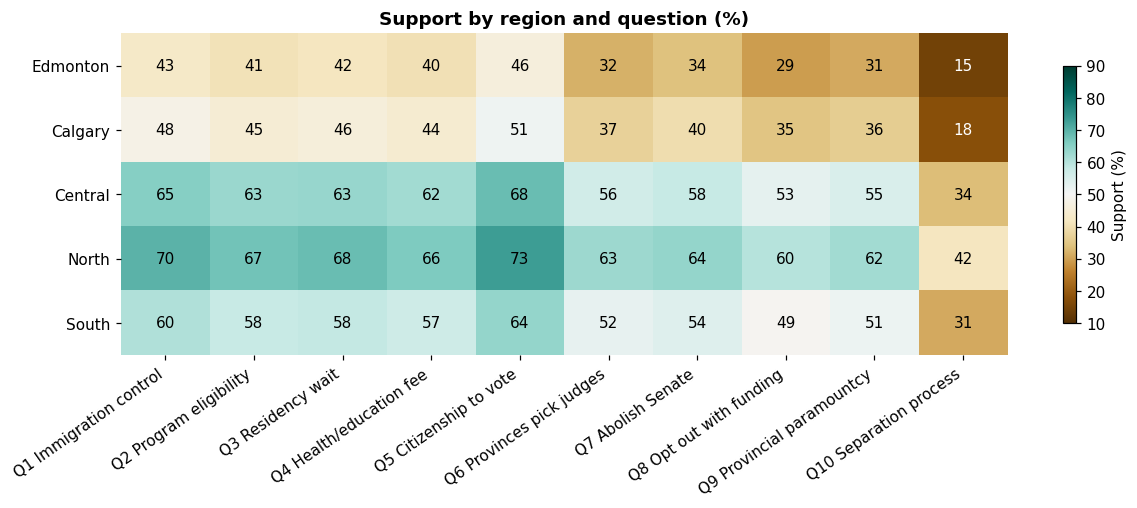

**What it shows.** The order of the regions barely changes. The North gave the most support on every question and Edmonton the least. The gap between the most and
least supportive region was 26 to 31 percentage points. Calgary was more supportive
than Edmonton on every question, by 3 to 5 points. Read across
a row and the drop from questions 1 to 5, to 6 to 9, to Question 10 is similar in every region.

In [15]:
vr = votes.merge(gdf[["ed_code", "region"]], on="ed_code")
reg = vr.groupby(["region", "question_number"])[["support_votes", "total"]].sum()
region_support = (100 * reg["support_votes"] / reg["total"]).unstack().reindex(REGION_ORDER)

fig, ax = plt.subplots(figsize=(13, 3.8))
im = ax.imshow(region_support.to_numpy(), cmap=SUPPORT_CMAP, norm=SUPPORT_NORM, aspect="auto")
for i in range(region_support.shape[0]):
    for j in range(region_support.shape[1]):
        v = region_support.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=10,
                color="white" if abs(v - 50) > 28 else "black")
ax.set_xticks(range(len(QS)))
ax.set_xticklabels([QUESTION_LABELS[q] for q in QS], rotation=35, ha="right")
ax.set_yticks(range(len(REGION_ORDER)))
ax.set_yticklabels(REGION_ORDER)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Support (%)")
ax.set_title("Support by region and question (%)")
plt.show()

top = region_support.idxmax().unique()
bottom = region_support.idxmin().unique()
gap = region_support.max() - region_support.min()
cal_minus_edm = region_support.loc["Calgary"] - region_support.loc["Edmonton"]
order_text = (f"The {top[0]} gave the most support on every question and {bottom[0]} the least."
              if len(top) == 1 and len(bottom) == 1 else
              "The most and least supportive regions vary a little between questions.")
note(f"""**What it shows.** The order of the regions barely changes. {order_text} The gap between the most and
least supportive region was {gap.min():.0f} to {gap.max():.0f} percentage points. Calgary was more supportive
than Edmonton on every question, by {cal_minus_edm.min():.0f} to {cal_minus_edm.max():.0f} points. Read across
a row and the drop from questions 1 to 5, to 6 to 9, to Question 10 is similar in every region.""")

## 12. One geography for every question
Two checks on how alike the ten questions are.

- **Clustering.** Moran's I (section 5) for each question, before and after removing regional averages (section 6).
- **Agreement between questions.** The correlation between two questions' results across ridings: 1 means the ridings that were most supportive on one question were also, in the same proportion, the most supportive on the other.

**How to read the chart.** Each line is one riding, coloured by region. Its height shows how far the riding was above or below the province-wide result on each question. If ridings kept the same position on every question, the lines would run roughly flat and parallel.

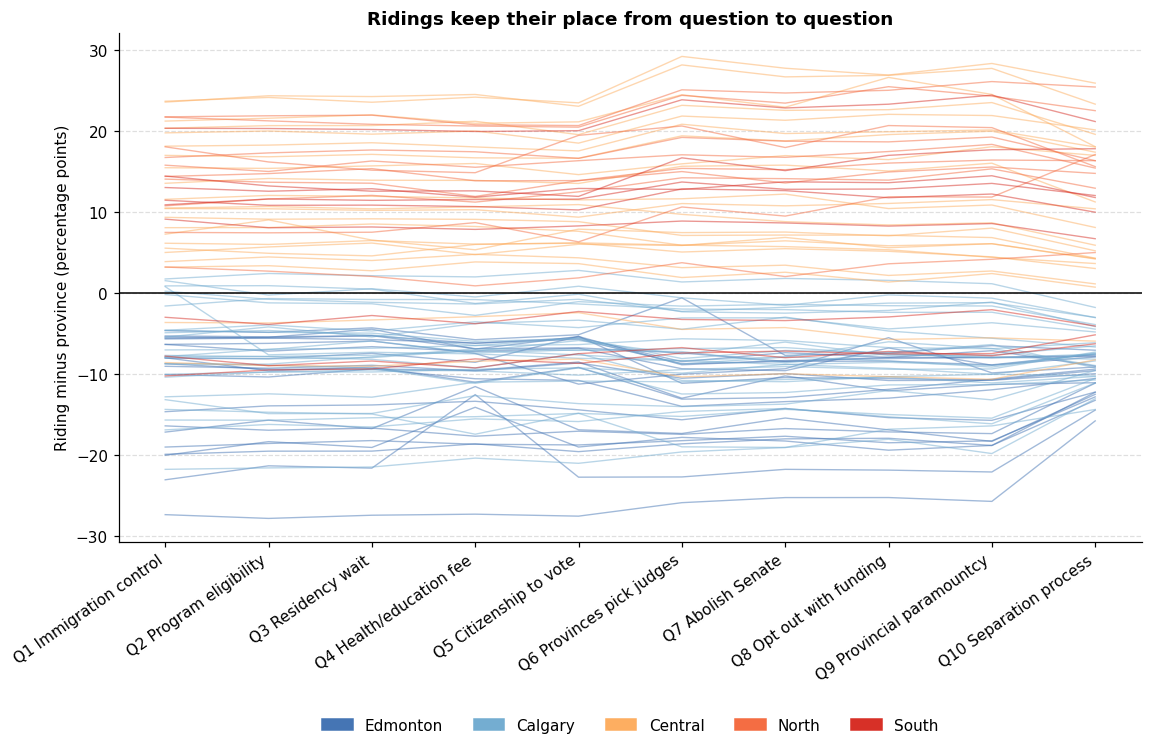

**What it shows.** Every question is strongly clustered (Moran's I from 0.70 to
0.74, all p ≤ 0.0001), and on every question most of that
clustering is the regional divide: within regions it falls to 0.11
to 0.19.

The questions are almost interchangeable as maps. The correlation between any two questions across ridings is
between 0.96 and 1.00, and a single shared pattern accounts for
99% of the differences between ridings across all ten questions. In plain terms: if you know how
a riding voted on one question, you can predict very closely how it voted on the others. The lines are not
perfectly parallel, though. At Question 10 they bunch closer together: with support low everywhere, ridings
differ by fewer points, and a few ridings move against the trend. Section 13 looks at those.

,Moran's I,p,Moran's I within regions,p (within regions)
Question,,,,
Q1 Immigration control,0.72,0.0001,0.17,0.0043
Q2 Program eligibility,0.72,0.0001,0.18,0.0035
Q3 Residency wait,0.73,0.0001,0.19,0.0017
Q4 Health/education fee,0.70,0.0001,0.15,0.0099
Q5 Citizenship to vote,0.72,0.0001,0.17,0.0051
Q6 Provinces pick judges,0.72,0.0001,0.15,0.0107
Q7 Abolish Senate,0.72,0.0001,0.15,0.0085
Q8 Opt out with funding,0.73,0.0001,0.15,0.0100
Q9 Provincial paramountcy,0.74,0.0001,0.15,0.0091


In [16]:
rows = []
for q in QS:
    yq = support[q].to_numpy()
    iq, pq, _ = moran_test(yq, W, N_PERMUTATIONS)
    rq = yq - pd.Series(yq).groupby(gdf["region"].to_numpy()).transform("mean").to_numpy()
    irq, prq, _ = moran_test(rq, W, N_PERMUTATIONS)
    rows.append({"Question": QUESTION_LABELS[q], "Moran's I": round(iq, 2), "p": round(pq, 4),
                 "Moran's I within regions": round(irq, 2), "p (within regions)": round(prq, 4)})
clustering = pd.DataFrame(rows).set_index("Question")

corr = support.corr()
off_diag = corr.where(~np.eye(len(QS), dtype=bool)).stack()
eig = np.linalg.eigvalsh(corr.to_numpy())
first_pattern = 100 * eig[-1] / eig.sum()

fig, ax = plt.subplots(figsize=(12, 6))
rel = support.sub(prov_support, axis=1)
for region in REGION_ORDER:
    for _, row in rel[gdf["region"].to_numpy() == region].iterrows():
        ax.plot(range(len(QS)), row.to_numpy(), color=REGION_COLOURS[region], alpha=0.5, linewidth=0.9)
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(range(len(QS)))
ax.set_xticklabels([QUESTION_LABELS[q] for q in QS], rotation=35, ha="right")
ax.set_ylabel("Riding minus province (percentage points)")
ax.set_title("Ridings keep their place from question to question")
ax.legend(handles=[mpatches.Patch(color=REGION_COLOURS[r], label=r) for r in REGION_ORDER],
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=5, frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

note(f"""**What it shows.** Every question is strongly clustered (Moran's I from {clustering["Moran's I"].min():.2f} to
{clustering["Moran's I"].max():.2f}, all p ≤ {clustering['p'].max():.4f}), and on every question most of that
clustering is the regional divide: within regions it falls to {clustering["Moran's I within regions"].min():.2f}
to {clustering["Moran's I within regions"].max():.2f}.

The questions are almost interchangeable as maps. The correlation between any two questions across ridings is
between {off_diag.min():.2f} and {off_diag.max():.2f}, and a single shared pattern accounts for
{first_pattern:.0f}% of the differences between ridings across all ten questions. In plain terms: if you know how
a riding voted on one question, you can predict very closely how it voted on the others. The lines are not
perfectly parallel, though. At Question 10 they bunch closer together: with support low everywhere, ridings
differ by fewer points, and a few ridings move against the trend. Section 13 looks at those.""")
clustering

## 13. Where Question 10 broke from the rest
Because the questions move together so closely, the interesting ridings are the ones that did **not** follow the pattern on Question 10. For each riding, we take its average support on questions 1 to 9 and see what Question 10 result that would predict, using the curve that best fits all 87 ridings. A riding above the curve gave Question 10 **more** support than its other answers would suggest; below the curve, **less**. The numbered ridings on the chart are the four furthest above and below, listed in the table under it.

**Caution.** This compares ridings, not people. A riding can sit above the curve for many reasons, including who turned out or who skipped the question.

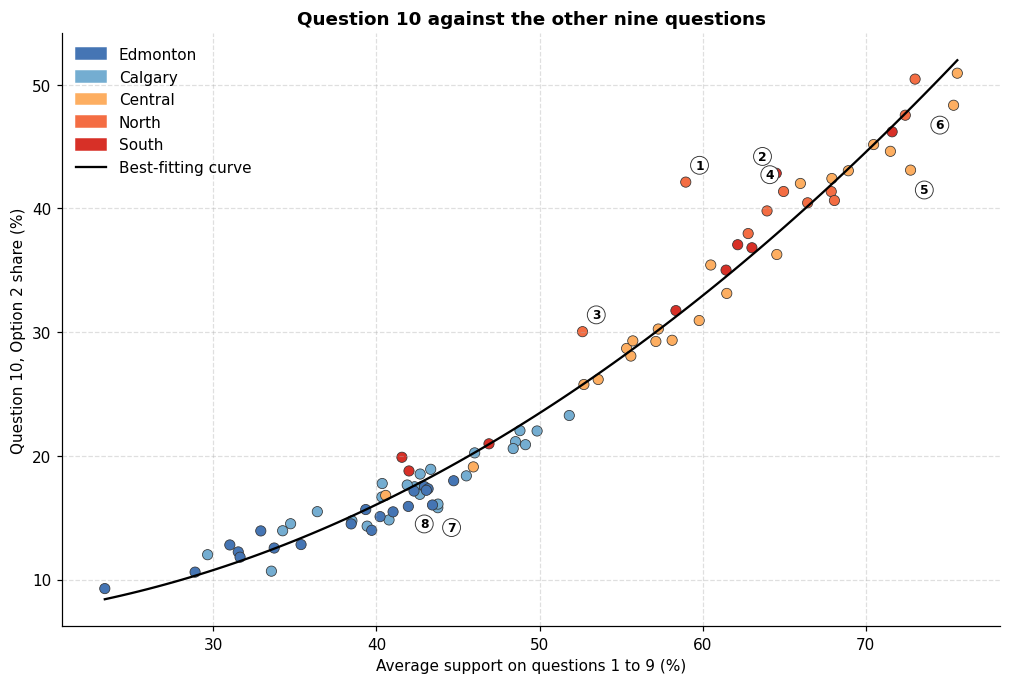

,Riding,Region,Points above (+) or below (-) the curve
Label,,,
1,Peace River,North,10.3
2,Cardston-Siksika,South,4.9
3,Lesser Slave Lake,North,4.3
4,Bonnyville-Cold Lake-St. Paul,North,2.9
5,Vermilion-Lloydminster-Wainwright,Central,-5.0
6,Drumheller-Stettler,Central,-3.3
7,Calgary-Cross,Calgary,-2.8
8,Calgary-North,Calgary,-2.5


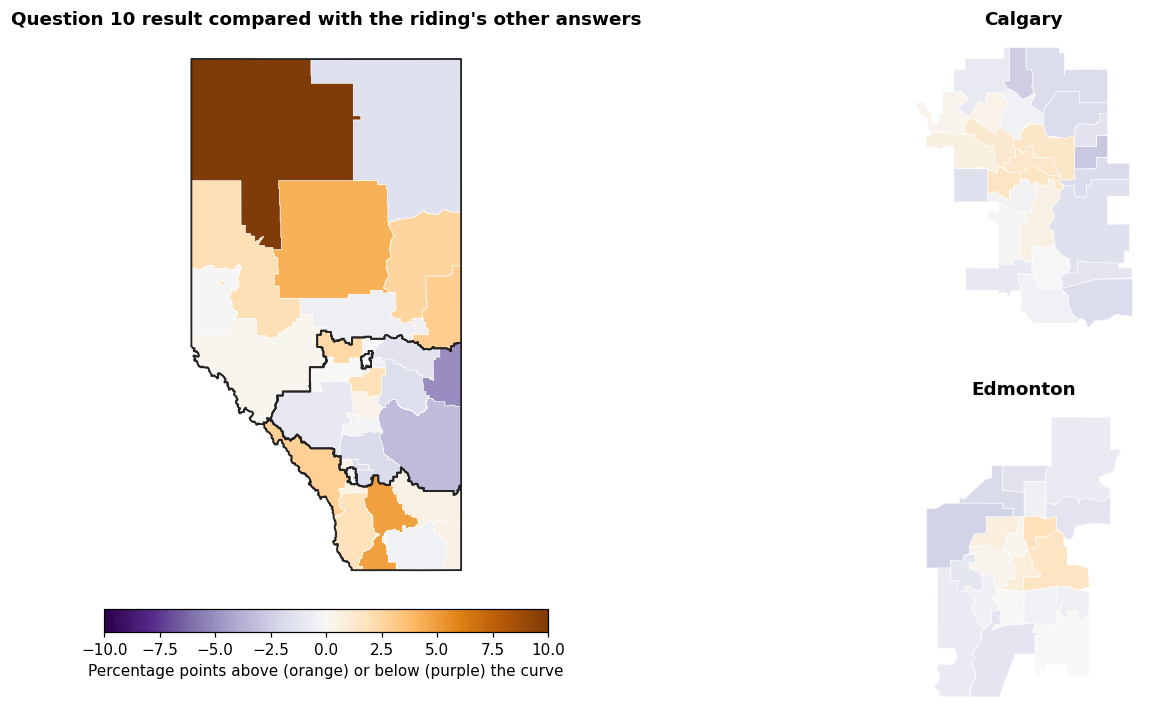

**What it shows.** The curve explains 97% of the differences in Question 10 results between
ridings, so a riding's other answers predict its Question 10 result closely. Departures from the curve are
small, but they are not random: they are themselves clustered on the map (Moran's I = 0.19, p = 0.0016).

- **More support for Question 10 than expected:** Peace River (+10.3), Cardston-Siksika (+4.9), Lesser Slave Lake (+4.3), Bonnyville-Cold Lake-St. Paul (+2.9).
- **Less support than expected:** Vermilion-Lloydminster-Wainwright (-5.0), Drumheller-Stettler (-3.3), Calgary-Cross (-2.8), Calgary-North (-2.5).
- **By region**, the average gap was largest in the North (+2.2 points) and
  most negative in Central (-0.7 points).

One reading is that some ridings backed the immigration and constitutional questions while drawing a line at
separation, and others were more open to separation than their other answers suggest. Explaining why would need
data on who lives in each riding, which this notebook does not have.

In [17]:
others = support[[q for q in QS if q != 10]].mean(axis=1).to_numpy()
q10 = support[10].to_numpy()
coef = np.polyfit(others, q10, 2)
fitted = np.polyval(coef, others)
gdf["q10_gap"] = q10 - fitted
r2 = 1 - np.sum((q10 - fitted) ** 2) / np.sum((q10 - q10.mean()) ** 2)
i_gap, p_gap, _ = moran_test(gdf["q10_gap"].to_numpy(), W, N_PERMUTATIONS)

n_label = 4
above = gdf.nlargest(n_label, "q10_gap")
below = gdf.nsmallest(n_label, "q10_gap")

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(others, q10, c=gdf["region"].map(REGION_COLOURS), s=45, edgecolor="#333333", linewidth=0.5)
xs = np.linspace(others.min(), others.max(), 100)
ax.plot(xs, np.polyval(coef, xs), color="black", linewidth=1.5, label="Best-fitting curve")
labelled = pd.concat([above, below])
for k, (i, r) in enumerate(labelled.iterrows(), start=1):
    ax.annotate(str(k), (others[i], q10[i]), xytext=(9 if k % 2 else -9, 11 if r["q10_gap"] > 0 else -13), textcoords="offset points",
                ha="center", va="center", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="#333333", lw=0.6))
ax.set_xlabel("Average support on questions 1 to 9 (%)")
ax.set_ylabel("Question 10, Option 2 share (%)")
ax.set_title("Question 10 against the other nine questions")
handles = [mpatches.Patch(color=REGION_COLOURS[r], label=r) for r in REGION_ORDER]
handles.append(plt.Line2D([0], [0], color="black", label="Best-fitting curve"))
ax.legend(handles=handles, loc="upper left", frameon=False)
ax.grid(linestyle="--", alpha=0.4)
plt.show()
display(pd.DataFrame({"Riding": labelled["ed_name"].str.title().to_numpy(),
                      "Region": labelled["region"].to_numpy(),
                      "Points above (+) or below (-) the curve": labelled["q10_gap"].round(1).to_numpy()},
                     index=pd.RangeIndex(1, len(labelled) + 1, name="Label")))

GAP_NORM = TwoSlopeNorm(vmin=-10, vcenter=0, vmax=10)
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1.0])
ax_main, ax_cal, ax_edm = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
for ax, sub in ((ax_main, gdf), (ax_cal, gdf[gdf["region"] == "Calgary"]), (ax_edm, gdf[gdf["region"] == "Edmonton"])):
    sub.plot(column="q10_gap", cmap="PuOr_r", norm=GAP_NORM, ax=ax, **RIDING_LINES)
    ax.set_axis_off()
outlines.boundary.plot(ax=ax_main, **REGION_LINES)
ax_main.set_title("Question 10 result compared with the riding's other answers")
ax_cal.set_title("Calgary")
ax_edm.set_title("Edmonton")
sm = plt.cm.ScalarMappable(norm=GAP_NORM, cmap="PuOr_r")
fig.colorbar(sm, ax=ax_main, orientation="horizontal", shrink=0.7, pad=0.02,
             label="Percentage points above (orange) or below (purple) the curve")
plt.show()

gap_by_region = gdf.groupby("region")["q10_gap"].mean().reindex(REGION_ORDER)
note(f"""**What it shows.** The curve explains {100 * r2:.0f}% of the differences in Question 10 results between
ridings, so a riding's other answers predict its Question 10 result closely. Departures from the curve are
small, but they are not random: they are themselves clustered on the map (Moran's I = {i_gap:.2f}, p = {p_gap:.4f}).

- **More support for Question 10 than expected:** {', '.join(f"{r['ed_name'].title()} (+{r['q10_gap']:.1f})" for _, r in above.iterrows())}.
- **Less support than expected:** {', '.join(f"{r['ed_name'].title()} ({r['q10_gap']:.1f})" for _, r in below.iterrows())}.
- **By region**, the average gap was largest in the {gap_by_region.idxmax()} ({gap_by_region.max():+.1f} points) and
  most negative in {gap_by_region.idxmin()} ({gap_by_region.min():+.1f} points).

One reading is that some ridings backed the immigration and constitutional questions while drawing a line at
separation, and others were more open to separation than their other answers suggest. Explaining why would need
data on who lives in each riding, which this notebook does not have.""")

## 14. Summary of findings

In [18]:
note(f"""1. **Option 2 lost province-wide** with {pct(prov_share, 2)} of valid votes and won a majority in only
   {len(over_50)} of 87 ridings ({', '.join(over_50['ed_name'].str.title())}), both just over 50%.
2. **Support was strongest in rural Alberta and weakest in the two big cities.** Median ridings ranged from
   {pct(med.min())} ({med.idxmin()}) to {pct(med.max())} ({med.idxmax()}).
3. **The map overstates Option 2.** Rural ridings dominate the map's area, but Calgary and Edmonton cast
   {pct(cities['Share of all valid votes'], 0)} of all valid votes.
4. **Support is strongly clustered** (Moran's I = {i_obs:.2f}, p = {p_obs:.4f}), and this holds for every definition
   of "neighbour" we tried.
5. **Most of that clustering is the difference between regions.** Within regions, clustering is much weaker
   (I = {i_res:.2f}, p = {p_res:.3f}).
6. **{len(hh)} ridings outside the cities form significant hotspots** and {len(ll)} city ridings form
   significant coldspots.
7. **Turnout shows no consistent relationship** with Option 2 support (rank correlation {rho_all:.2f}).

**Part 2: all ten questions**

8. **The immigration and voting questions (1 to 5) won majorities; the constitutional questions (6 to 9) and
   Question 10 did not.** Province-wide support ran from {pct(prov_support.max())} ({QUESTION_LABELS[prov_support.idxmax()]})
   to {pct(prov_support.min())} ({QUESTION_LABELS[prov_support.idxmin()]}).
9. **Every question has the same geography.** Results correlate at {off_diag.min():.2f} or higher across ridings, one
   shared pattern accounts for {first_pattern:.0f}% of the differences between ridings, and the regions line up in
   the same order on every question.
10. **What differs between questions is the level of support, not where it comes from.** Question 10 drew far less
   support everywhere, but from the same places.
11. **A few ridings broke the pattern on Question 10**, most of all {above.iloc[0]['ed_name'].title()} ({above.iloc[0]['q10_gap']:+.1f}
   points above what its other answers predict) and {below.iloc[0]['ed_name'].title()} ({below.iloc[0]['q10_gap']:+.1f}).""")

1. **Option 2 lost province-wide** with 25.05% of valid votes and won a majority in only
   2 of 87 ridings (Rimbey-Rocky Mountain House-Sundre, Central Peace-Notley), both just over 50%.
2. **Support was strongest in rural Alberta and weakest in the two big cities.** Median ridings ranged from
   14.8% (Edmonton) to 41.0% (North).
3. **The map overstates Option 2.** Rural ridings dominate the map's area, but Calgary and Edmonton cast
   52% of all valid votes.
4. **Support is strongly clustered** (Moran's I = 0.73, p = 0.0001), and this holds for every definition
   of "neighbour" we tried.
5. **Most of that clustering is the difference between regions.** Within regions, clustering is much weaker
   (I = 0.11, p = 0.033).
6. **22 ridings outside the cities form significant hotspots** and 20 city ridings form
   significant coldspots.
7. **Turnout shows no consistent relationship** with Option 2 support (rank correlation -0.18).

**Part 2: all ten questions**

8. **The immigration and voting questions (1 to 5) won majorities; the constitutional questions (6 to 9) and
   Question 10 did not.** Province-wide support ran from 58.1% (Q5 Citizenship to vote)
   to 25.1% (Q10 Separation process).
9. **Every question has the same geography.** Results correlate at 0.96 or higher across ridings, one
   shared pattern accounts for 99% of the differences between ridings, and the regions line up in
   the same order on every question.
10. **What differs between questions is the level of support, not where it comes from.** Question 10 drew far less
   support everywhere, but from the same places.
11. **A few ridings broke the pattern on Question 10**, most of all Peace River (+10.3
   points above what its other answers predict) and Vermilion-Lloydminster-Wainwright (-5.0).

## Limitations and next steps
**What this analysis does not show.**
- **Why** places voted as they did. There are no explanatory variables yet (income, industry, age, past party vote). The original notebook included a regression, but its explanatory variables were randomly generated, so it was removed.
- **How individuals voted.** All results are for ridings. A pattern across ridings need not hold for the people in them.

**Known weaknesses.**
- The region labels have not been checked against an official source, and sections 3, 4, 6, 8, 11 and 12 depend on them.
- Part 2 compares answers across questions by riding. A riding that backed two questions did not necessarily do so through the same voters.
- Boundary lines are simplified. This does not change which ridings border each other in any way that matters here, but the maps are not survey-grade.

**Next steps.**
- Verify the region labels, or replace them with an official grouping.
- Add real explanatory data, for example Statistics Canada census profiles by electoral division or 2023 provincial election results, and then fit a spatial regression.
- Look at who lives in the ridings that broke the pattern on Question 10 (section 13).

## Glossary
- **Riding / electoral division.** One of Alberta's 87 districts that each elect one MLA. Results are reported by riding.
- **Option 2 share.** Option 2 votes divided by Option 1 + Option 2 votes, as a percentage. Declined and rejected ballots are excluded.
- **Support (Part 2).** The Yes share for questions 1 to 9 and the Option 2 share for Question 10, as a percentage of valid votes.
- **Region.** One of five groups of ridings used here: Calgary, Edmonton (city ridings only), Central, North and South.
- **Neighbours.** Ridings that share a border. Section 5 also tries "the k nearest ridings".
- **Moran's I.** One number summarising how alike neighbouring ridings are. About 0 means no pattern; closer to 1 means neighbours are very alike; negative means neighbours tend to differ.
- **Permutation test / shuffling.** Randomly reassigning the results to ridings many times to see what a map with no geographic pattern looks like, then comparing the real map with those shuffled maps.
- **p-value.** The share of shuffled maps that looked at least as clustered as the real one. Small values (below 0.05 here) mean the pattern is unlikely to be chance. With 9,999 shuffles, the smallest possible value is 0.0001.
- **LISA (local Moran's I).** A version of Moran's I for each riding, used to label hotspots, coldspots and outliers.
- **Standard units.** A value's distance from the average riding, measured in standard deviations. 0 is average; +1 is one standard deviation above.
- **Correlation.** How closely two sets of numbers rise and fall together across ridings, from -1 (opposite) through 0 (unrelated) to 1 (move together exactly).
- **Shared pattern.** The single combination of all ten questions that best describes how ridings differ. Its percentage says how much of the riding-to-riding differences it captures.
- **Rank correlation (Spearman).** How consistently one measure rises as another rises, from -1 (always falls) through 0 (no relationship) to 1 (always rises).